# Missão Pulso Zero — minijogo 3D em OpenGL com Python

**Trabalho Prático 1 — Computação Gráfica (IFSULDEMINAS, Campus Machado)**
**Integrantes:** _Nome 1_ e _Nome 2_ (substitua antes da entrega)

Uma estação espacial perdeu sua fonte principal de energia. Um drone de manutenção precisa recuperar **cinco células de energia**, desviar de **obstáculos** e alcançar o **portal de saída**, que só se abre depois da coleta.

Vamos construir o jogo em etapas, no mesmo estilo das práticas anteriores: Python + **Pygame** (janela e teclado) + **PyOpenGL** (OpenGL clássico 2.1) + **Pillow** (imagens das texturas).

## Objetivos

- construir uma cena 3D por código (piso, paredes, drone composto, células, obstáculos e portal);
- aplicar translação, rotação e escala, inclusive em **transformações hierárquicas**;
- usar perspectiva, câmera (`gluLookAt`) e teste de profundidade;
- animar com `dt`: rotação contínua, movimento periódico e animações por evento;
- aplicar **texturas** com UV e repetição, **normais** e **iluminação** (ambiente + difusa + especular);
- tratar teclado, limites, colisões simples, coleta e reinício.

**Ambiente:** Jupyter local ou VS Code, com interface gráfica e driver OpenGL. O jogo abre uma janela externa e a célula continua executando enquanto ela estiver aberta. Feche com **Esc**. Não roda diretamente no Colab.

## Controles

| Tecla | Ação |
|---|---|
| W, A, S, D | Movimentar o drone (relativo à câmera) |
| Setas ← → | Girar a câmera ao redor do drone |
| Setas ↑ ↓ | Subir/descer a câmera |
| Roda do mouse | Aproximar/afastar a câmera |
| C | Alternar câmera: seguindo o drone / vista aérea |
| L | Ligar/desligar a fonte de luz |
| Q, E | Mover a luz ao redor da arena |
| R | Reiniciar a missão |
| Esc | Encerrar |

## Etapa 1 — Instalar as bibliotecas

`pygame` cria a janela e lê o teclado, `PyOpenGL` acessa a API gráfica e `Pillow` gera as imagens das texturas. Execute a célula abaixo uma única vez, no kernel em que fará a prática.

In [1]:
%pip install pygame PyOpenGL Pillow

  Using cached pygame-2.6.1-cp313-cp313-win_amd64.whl.metadata (13 kB)
  Using cached pyopengl-3.1.10-py3-none-any.whl.metadata (3.3 kB)
  Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
Using cached pygame-2.6.1-cp313-cp313-win_amd64.whl (10.6 MB)
Using cached pyopengl-3.1.10-py3-none-any.whl (3.2 MB)
Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl (7.3 MB)

   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   ---------------------------------------- 0/3 [PyOpenGL]
   -----------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Etapa 2 — Importar os recursos

`GL` contém os comandos de desenho e de estado. `GLU` fornece câmera, projeção e quádricas (esfera, cilindro, disco). `Path` localiza a pasta `texturas/` **relativa ao arquivo**, sem caminhos do computador dos autores.

**Verificação:** se algum import falhar, reinicie o kernel. A biblioteca GLU precisa existir no sistema (no Ubuntu, `libglu1-mesa`).

In [1]:
import math
import random
import sys
from contextlib import contextmanager
from pathlib import Path

import pygame
from PIL import Image, ImageDraw
from OpenGL.GL import *
from OpenGL.GLU import (gluPerspective, gluLookAt, gluNewQuadric, gluQuadricNormals,
                        gluQuadricTexture, gluSphere, gluCylinder, gluDisk,
                        gluBuild2DMipmaps, GLU_SMOOTH)

# Pasta do projeto: funciona tanto como script (.py) quanto dentro do notebook.
try:
    BASE = Path(__file__).resolve().parent
except NameError:
    BASE = Path.cwd()
PASTA_TEXTURAS = BASE / "texturas"
print("Bibliotecas importadas.")

pygame 2.6.1 (SDL 2.28.4, Python 3.13.17)
Hello from the pygame community. https://www.pygame.org/contribute.html
Bibliotecas importadas.


## Etapa 3 — Identidade visual e parâmetros

Todos os números do jogo ficam reunidos aqui. Durante a apresentação, basta mudar uma constante para alterar a velocidade do drone, a posição da luz ou o tamanho de um objeto.

**Identidade visual**

- **Nome da missão:** Missão Pulso Zero.
- **Cenário:** laboratório de manutenção em órbita, com piso metálico e painéis azul-acinzentados.
- **Células de energia:** cilindros **âmbar** que giram e flutuam (coletáveis).
- **Obstáculos:** caixas de manutenção **laranja** com faixas de perigo.
- **Portal:** vermelho enquanto bloqueado, **verde-água** quando liberado.
- **Drone:** corpo azul metálico, cúpula ciano, sensor vermelho na frente e anéis laranja (frente) e ciano (trás).

**Sistema de coordenadas do mundo:** `x` para a direita, `y` para cima e `z` para a câmera inicial. O piso fica em `y = 0` e o drone voa em altura aproximadamente constante.

In [2]:
# ----- Janela e tempo -----
LARGURA, ALTURA = 1100, 700
FPS = 60
NOME_MISSAO = "Missão Pulso Zero"

# ----- Arena (coordenadas do mundo) -----
LADO = 12.0            # o piso vai de -LADO a +LADO em x e z
ALTURA_PAREDE = 2.5
TILE_PISO = 2.0        # lado do mundo coberto por UMA cópia da textura do piso
TILE_PAREDE = 2.5
TILE_CAIXA = 2.0

# ----- Drone -----
POS_INICIAL = (0.0, 9.0)   # (x, z)
ALTURA_VOO = 1.3
ESCALA_DRONE = 0.55
RAIO_DRONE = 0.7           # raio de colisão (círculo no plano horizontal)
VEL_MAX = 6.5              # unidades por segundo
ACELERACAO = 20.0          # unidades por segundo²
VEL_GIRO = 540.0           # graus por segundo (giro do rumo)
GIRO_HELICE = 1800.0       # graus por segundo
INCLINACAO_MAX = 14.0      # graus

# ----- Regras -----
RAIO_COLETA = 1.0
TEMPO_COLETA = 0.55        # duração da animação de coleta (s)
TEMPO_ABERTURA = 1.6       # duração da animação de abertura do portal (s)
TEMPO_IMPACTO = 0.6        # duração do alerta de colisão (s)
PERIODO_FLUTUAR = 2.4      # período do sobe-e-desce das células (s)
PORTAL_POS = (0.0, -10.6)  # (x, z)
RAIO_PORTAL = 1.2

# Células de energia: (x, z)
POS_CELULAS = [(-8.0, 6.5), (8.0, 7.0), (0.5, 0.5), (-8.5, -8.0), (8.5, -8.5)]

# Obstáculos: (x, z, meia-largura em x, meia-altura em y, meia-largura em z)
OBSTACULOS = [
    (-5.0, 3.0, 1.0, 1.0, 1.0),
    (4.5, 0.5, 1.4, 0.9, 0.9),
    (-3.0, -4.5, 0.9, 1.1, 1.6),
    (5.0, -6.5, 1.1, 1.3, 1.1),
]

# ----- Iluminação -----
LUZ_ALTURA = 7.0
LUZ_RAIO = 5.0
LUZ_VELOCIDADE = 60.0                  # graus por segundo ao usar Q/E
AMBIENTE_GLOBAL = (0.28, 0.30, 0.36, 1.0)

# ----- Paleta -----
COR = {
    "fundo": (0.02, 0.03, 0.07),
    "celula": (1.0, 0.78, 0.12),
    "obstaculo": (1.0, 0.55, 0.35),
    "portal_fechado": (0.95, 0.15, 0.15),
    "portal_aberto": (0.15, 1.0, 0.75),
    "drone": (0.32, 0.42, 0.62),
}


def clamp(valor, minimo, maximo):
    return max(minimo, min(maximo, valor))


def misturar(a, b, t):
    """Interpolação linear entre duas cores."""
    return tuple(x + (y - x) * t for x, y in zip(a, b))

## Etapa 4 — Criar as imagens das texturas

Para o projeto não depender de downloads nem de caminhos locais, as três texturas são **geradas por código com Pillow**. Esta é a **origem das imagens**: todas foram desenhadas pelos autores, sem imagens de terceiros.

| Textura | Uso | Repetição |
|---|---|---|
| `piso` | piso metálico: placas com parafusos e riscos | repete a cada 2 unidades do mundo |
| `painel` | paredes, caixas e estrutura do portal (faixas de perigo) | repete conforme o tamanho da face |
| `celula` | rótulo das células de energia (raios) | uma volta no cilindro |

Se existir `texturas/piso.png`, `texturas/painel.png` ou `texturas/celula.png`, o jogo usa o arquivo no lugar da imagem gerada. A função `salvar_texturas()` grava as imagens geradas nessa pasta para que sejam entregues junto com o código.

As imagens do piso e do painel são **repetíveis** (as bordas se encaixam), por isso a repetição não mostra emendas evidentes.

In [3]:
def criar_imagem_piso(tam=256):
    """Piso metálico: quatro placas com moldura, parafusos e pequenos riscos."""
    rng = random.Random(7)
    img = Image.new("RGB", (tam, tam), (96, 108, 126))
    d = ImageDraw.Draw(img)
    m = tam // 2
    for i in range(2):
        for j in range(2):
            x0, y0 = i * m, j * m
            tom = 118 if (i + j) % 2 == 0 else 104
            d.rectangle((x0, y0, x0 + m - 1, y0 + m - 1), fill=(tom, tom + 12, tom + 30))
            d.rectangle((x0, y0, x0 + m - 1, y0 + m - 1), outline=(46, 54, 68), width=4)
            d.rectangle((x0 + 7, y0 + 7, x0 + m - 8, y0 + m - 8), outline=(150, 164, 184), width=1)
            for px, py in ((14, 14), (m - 15, 14), (14, m - 15), (m - 15, m - 15)):
                d.ellipse((x0 + px - 5, y0 + py - 5, x0 + px + 5, y0 + py + 5),
                          fill=(60, 68, 84), outline=(170, 182, 200))
    for _ in range(45):  # riscos
        x, y = rng.randrange(tam), rng.randrange(tam)
        c = rng.randrange(140, 175)
        d.line((x, y, x + rng.randrange(6, 24), y + rng.randrange(-2, 3)), fill=(c, c + 8, c + 20))
    return img


def criar_imagem_painel(tam=256):
    """Painel de manutenção: faixas de perigo, moldura, travessas e parafusos."""
    img = Image.new("RGB", (tam, tam), (92, 104, 126))
    d = ImageDraw.Draw(img)
    faixa = 30
    for y0 in (0, tam - faixa):
        d.rectangle((0, y0, tam, y0 + faixa), fill=(38, 40, 46))
        for x0 in range(-faixa, tam, 32):  # período 32 = repetição sem emenda
            d.polygon([(x0, y0 + faixa), (x0 + 16, y0 + faixa),
                       (x0 + 16 + faixa, y0), (x0 + faixa, y0)], fill=(255, 140, 40))
    topo, base = faixa + 12, tam - faixa - 13
    d.rectangle((14, topo, tam - 15, base), fill=(108, 122, 146), outline=(40, 48, 62), width=4)
    d.line((14, topo, tam - 15, base), fill=(66, 76, 94), width=5)
    d.line((14, base, tam - 15, topo), fill=(66, 76, 94), width=5)
    for px, py in ((28, topo + 14), (tam - 29, topo + 14), (28, base - 14), (tam - 29, base - 14)):
        d.ellipse((px - 5, py - 5, px + 5, py + 5), fill=(52, 60, 76), outline=(170, 182, 200))
    return img


def criar_imagem_celula(larg=512, alt=256):
    """Rótulo da célula de energia: fundo âmbar, faixas escuras e dois raios."""
    img = Image.new("RGB", (larg, alt), (255, 190, 40))
    d = ImageDraw.Draw(img)
    for y in range(alt):  # gradiente vertical simula curvatura
        f = 0.70 + 0.30 * math.sin(math.pi * y / alt)
        d.line((0, y, larg, y), fill=(int(255 * f), int(190 * f), int(40 * f)))
    escuro = (45, 34, 18)
    d.rectangle((0, 0, larg, 22), fill=escuro)
    d.rectangle((0, alt - 23, larg, alt), fill=escuro)
    raio = [(12, -80), (-46, 12), (-8, 12), (-22, 80), (48, -22), (8, -22)]
    for cx in (larg // 4, 3 * larg // 4):
        d.polygon([(cx + x, alt // 2 + y) for x, y in raio], fill=escuro)
    return img


GERADORES = {"piso": criar_imagem_piso, "painel": criar_imagem_painel, "celula": criar_imagem_celula}


def obter_imagem(nome):
    """Usa texturas/<nome>.png se existir; caso contrário, gera a imagem."""
    caminho = PASTA_TEXTURAS / f"{nome}.png"
    if caminho.exists():
        with Image.open(caminho) as arquivo:
            return arquivo.convert("RGB")
    return GERADORES[nome]()


def salvar_texturas():
    """Grava as imagens geradas em texturas/ (para entregar com o projeto)."""
    PASTA_TEXTURAS.mkdir(exist_ok=True)
    for nome, gerar in GERADORES.items():
        destino = PASTA_TEXTURAS / f"{nome}.png"
        gerar().save(destino)
        print("Salvo:", destino)

piso


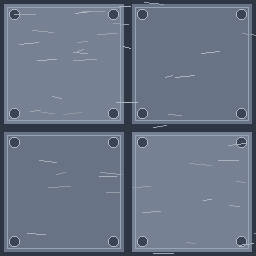

painel


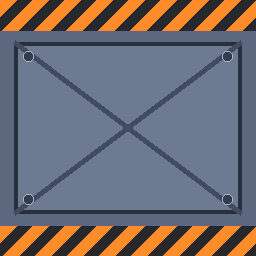

celula


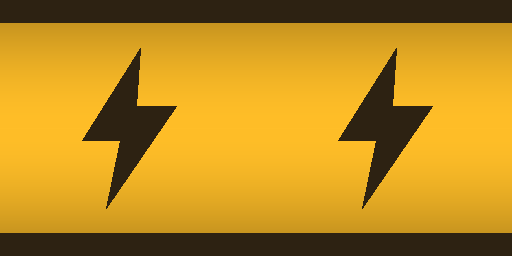

In [4]:
from IPython.display import display

for nome, gerar in GERADORES.items():
    print(nome)
    display(gerar())

**Verificação:** você deve ver um piso de placas metálicas, um painel com faixas laranja e um rótulo âmbar com dois raios. Nenhuma delas foi enviada ao OpenGL ainda.

## Etapa 5 — Enviar a textura à GPU

Esta função só pode ser chamada **depois** de a janela e o contexto OpenGL existirem.

1. A imagem é convertida para RGB e suas linhas são invertidas para a convenção de UV usada pelo OpenGL (origem embaixo à esquerda).
2. `glGenTextures` cria o identificador e `glBindTexture` seleciona a textura.
3. `gluBuild2DMipmaps` envia a imagem e cria **mipmaps**. Eles evitam cintilação no piso, que se estende até longe da câmera.
4. `GL_REPEAT` permite coordenadas UV maiores que 1, o que repete a imagem.

In [5]:
def enviar_textura(imagem):
    imagem = imagem.convert("RGB").transpose(Image.Transpose.FLIP_TOP_BOTTOM)
    textura = int(glGenTextures(1))
    glBindTexture(GL_TEXTURE_2D, textura)
    glPixelStorei(GL_UNPACK_ALIGNMENT, 1)
    gluBuild2DMipmaps(GL_TEXTURE_2D, GL_RGB, imagem.width, imagem.height,
                      GL_RGB, GL_UNSIGNED_BYTE, imagem.tobytes())
    glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_MIN_FILTER, GL_LINEAR_MIPMAP_LINEAR)
    glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_MAG_FILTER, GL_LINEAR)
    glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_WRAP_S, GL_REPEAT)
    glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_WRAP_T, GL_REPEAT)
    return textura

## Etapa 6 — Geometria: faces, normais, UV e display lists

Cada objeto é definido em **coordenadas locais** (espaço do objeto), em torno da origem. A posição no mundo vem depois, com `glTranslatef`.

- **Cubo:** vai de −1 a +1. Cada face tem quatro vértices em ordem anti-horária (vista de fora) e **uma normal**, a mesma ideia da prática de texturas.
- **UV proporcionais:** `emitir_face` calcula as coordenadas de textura pelo **tamanho real da face** dividido por `tile`. Uma face de 24 unidades com `tile = 2` recebe UV de 0 a 12, ou seja, a textura repete 12 vezes sem esticar.
- **Subdivisão:** cada face é dividida em quadrados. A iluminação clássica é calculada **por vértice**; sem subdivisão, um piso com quatro vértices não mostraria o brilho da lâmpada.
- **Display lists:** a geometria é gravada uma vez (`glNewList`) e depois chamada com `glCallList`. Assim o Python não precisa enviar milhares de vértices a cada quadro.
- **Quádricas GLU:** esfera, cilindro, disco e anel já trazem normais suaves.
- **Paredes:** são faces **voltadas para dentro**, com `GL_CULL_FACE`. Quando a câmera passa para fora da arena, a parede não bloqueia a visão.
- **Estrelas:** primitiva `GL_POINTS`, desenhada ao fundo.

In [6]:
# Cada face: (normal, vértices em ordem anti-horária vista de fora).
FACES = [
    ((0, 0, 1),  [(-1, -1, 1), (1, -1, 1), (1, 1, 1), (-1, 1, 1)]),
    ((0, 0, -1), [(1, -1, -1), (-1, -1, -1), (-1, 1, -1), (1, 1, -1)]),
    ((1, 0, 0),  [(1, -1, 1), (1, -1, -1), (1, 1, -1), (1, 1, 1)]),
    ((-1, 0, 0), [(-1, -1, -1), (-1, -1, 1), (-1, 1, 1), (-1, 1, -1)]),
    ((0, 1, 0),  [(-1, 1, 1), (1, 1, 1), (1, 1, -1), (-1, 1, -1)]),
    ((0, -1, 0), [(-1, -1, -1), (1, -1, -1), (1, -1, 1), (-1, -1, 1)]),
]


def emitir_face(normal, vertices, escala, tile, passo):
    """Emite uma face subdividida (use dentro de glBegin(GL_QUADS)).

    escala: multiplica as coordenadas do vértice (meias-dimensões da caixa).
    tile:   tamanho do mundo coberto por UMA cópia da textura.
    passo:  tamanho aproximado de cada quadrado da subdivisão.
    """
    sx, sy, sz = escala
    p0, p1, p2, p3 = [(x * sx, y * sy, z * sz) for x, y, z in vertices]
    a = tuple(p1[i] - p0[i] for i in range(3))   # aresta que corre em U
    b = tuple(p3[i] - p0[i] for i in range(3))   # aresta que corre em V
    larg = math.sqrt(sum(c * c for c in a))
    alt = math.sqrt(sum(c * c for c in b))
    nu, nv = max(1, round(larg / passo)), max(1, round(alt / passo))
    umax, vmax = larg / tile, alt / tile         # UV pelo tamanho real da face
    glNormal3f(*normal)
    for i in range(nu):
        for j in range(nv):
            for s, t in ((i / nu, j / nv), ((i + 1) / nu, j / nv),
                         ((i + 1) / nu, (j + 1) / nv), (i / nu, (j + 1) / nv)):
                glTexCoord2f(s * umax, t * vmax)
                glVertex3f(p0[0] + a[0] * s + b[0] * t,
                           p0[1] + a[1] * s + b[1] * t,
                           p0[2] + a[2] * s + b[2] * t)


def criar_lista(faces, escala=(1, 1, 1), tile=2.0, passo=1.0):
    lista = glGenLists(1)
    glNewList(lista, GL_COMPILE)
    glBegin(GL_QUADS)
    for normal, vertices in faces:
        emitir_face(normal, vertices, escala, tile, passo)
    glEnd()
    glEndList()
    return lista


def criar_lista_quadrica(desenhar, textura=False):
    q = gluNewQuadric()
    gluQuadricNormals(q, GLU_SMOOTH)
    gluQuadricTexture(q, GL_TRUE if textura else GL_FALSE)
    lista = glGenLists(1)
    glNewList(lista, GL_COMPILE)
    desenhar(q)
    glEndList()
    return lista


def criar_lista_helice():
    """Duas pás cruzadas, no plano XZ, centradas na origem (gira em torno de Y)."""
    lista = glGenLists(1)
    glNewList(lista, GL_COMPILE)
    glBegin(GL_QUADS)
    glNormal3f(0, 1, 0)
    for cx, cz in ((0.42, 0.05), (0.05, 0.42)):
        glVertex3f(-cx, 0, cz)
        glVertex3f(cx, 0, cz)
        glVertex3f(cx, 0, -cz)
        glVertex3f(-cx, 0, -cz)
    glEnd()
    glEndList()
    return lista


def criar_lista_estrelas(quantidade=350):
    """Céu: pontos (GL_POINTS) numa semiesfera grande, com sementes fixas."""
    rng = random.Random(42)
    lista = glGenLists(1)
    glNewList(lista, GL_COMPILE)
    glBegin(GL_POINTS)
    for _ in range(quantidade):
        y = rng.uniform(-0.15, 1.0)
        raio = math.sqrt(1.0 - y * y)
        ang = rng.uniform(0.0, 2.0 * math.pi)
        brilho = rng.uniform(0.5, 1.0)
        glColor3f(brilho, brilho, min(1.0, brilho + 0.15))
        glVertex3f(80 * raio * math.cos(ang), 80 * y, 80 * raio * math.sin(ang))
    glEnd()
    glEndList()
    return lista


def parede(normal, vertices):
    return criar_lista([(normal, vertices)], tile=TILE_PAREDE, passo=2.0)


def criar_geometria():
    """Cria todas as display lists. Chamar depois de abrir a janela."""
    L = {}
    L["cubo"] = criar_lista(FACES, (1, 1, 1), tile=2.0, passo=99)
    L["esfera"] = criar_lista_quadrica(lambda q: gluSphere(q, 1.0, 24, 16), textura=True)
    L["cilindro"] = criar_lista_quadrica(lambda q: gluCylinder(q, 1.0, 1.0, 1.0, 24, 1), textura=True)
    L["disco"] = criar_lista_quadrica(lambda q: gluDisk(q, 0.0, 1.0, 24, 1))
    L["anel"] = criar_lista_quadrica(lambda q: gluDisk(q, 0.80, 1.0, 32, 1))
    L["helice"] = criar_lista_helice()
    L["estrelas"] = criar_lista_estrelas()

    # Piso: caixa fina (sem a face de baixo); o topo fica em y = 0.
    faces_piso = [f for i, f in enumerate(FACES) if i != 5]
    L["piso"] = criar_lista(faces_piso, (LADO, 0.3, LADO), tile=TILE_PISO, passo=1.0)

    # Paredes: uma face voltada para dentro por lado (normal para o centro da arena).
    d, h = LADO, ALTURA_PAREDE
    L["paredes"] = [
        parede((0, 0, 1),  [(-d, 0, -d), (d, 0, -d), (d, h, -d), (-d, h, -d)]),
        parede((0, 0, -1), [(d, 0, d), (-d, 0, d), (-d, h, d), (d, h, d)]),
        parede((-1, 0, 0), [(d, 0, -d), (d, 0, d), (d, h, d), (d, h, -d)]),
        parede((1, 0, 0),  [(-d, 0, d), (-d, 0, -d), (-d, h, -d), (-d, h, d)]),
    ]

    # Obstáculos, pilares e viga do portal: caixas com UV proporcional ao tamanho.
    L["obstaculos"] = [criar_lista(FACES, (hx, hy, hz), tile=TILE_CAIXA, passo=1.0)
                       for (_, _, hx, hy, hz) in OBSTACULOS]
    L["pilar"] = criar_lista(FACES, (0.3, 1.15, 0.3), tile=TILE_CAIXA, passo=1.0)
    L["viga"] = criar_lista(FACES, (1.9, 0.2, 0.3), tile=TILE_CAIXA, passo=1.0)
    return L

## Etapa 7 — Materiais, luz e utilitários de desenho

**Material:** na iluminação clássica, `glMaterialfv` define como a superfície responde à luz.

- `AMBIENT_AND_DIFFUSE`: cor base (difusa);
- `SPECULAR` + `SHININESS`: tamanho e intensidade do **brilho especular**;
- `EMISSION`: luz própria do objeto (células, sensor, portal).

Como `GL_COLOR_MATERIAL` está desligado, `glColor` **não** muda a cor de objetos iluminados; quem manda é o material.

**Luz:** `GL_LIGHT0` é uma fonte pontual (posição com `w = 1`) com atenuação por distância. A contribuição **ambiente** (`GL_LIGHT_MODEL_AMBIENT`) existe mesmo com a lâmpada desligada, por isso a cena continua visível, só que sem relevo. A posição da luz é definida **depois** de `gluLookAt` e **antes** dos objetos, então a luz fica fixa no mundo.

**Utilitários:** os blocos `with` desligam luz ou ativam transparência e restauram o estado ao sair, evitando "vazar" configuração para o próximo objeto.

In [7]:
T = {}   # identificadores das texturas
L = {}   # display lists


def material(cor, especular=0.0, brilho=10.0, emissao=(0.0, 0.0, 0.0)):
    glMaterialfv(GL_FRONT_AND_BACK, GL_AMBIENT_AND_DIFFUSE, (*cor, 1.0))
    glMaterialfv(GL_FRONT_AND_BACK, GL_SPECULAR, (especular, especular, especular, 1.0))
    glMaterialf(GL_FRONT_AND_BACK, GL_SHININESS, brilho)
    glMaterialfv(GL_FRONT_AND_BACK, GL_EMISSION, (*emissao, 1.0))


def usar_textura(textura):
    """Liga a textura indicada ou desliga o texturamento (None)."""
    if textura is None:
        glDisable(GL_TEXTURE_2D)
    else:
        glEnable(GL_TEXTURE_2D)
        glBindTexture(GL_TEXTURE_2D, textura)


@contextmanager
def sem_iluminacao():
    """Desenha com cor direta (linhas, pontos, HUD, efeitos)."""
    glDisable(GL_LIGHTING)
    glDisable(GL_TEXTURE_2D)
    try:
        yield
    finally:
        glEnable(GL_LIGHTING)


@contextmanager
def modo_transparente():
    glEnable(GL_BLEND)
    glBlendFunc(GL_SRC_ALPHA, GL_ONE_MINUS_SRC_ALPHA)
    glDepthMask(GL_FALSE)      # transparentes não escrevem profundidade
    try:
        yield
    finally:
        glDepthMask(GL_TRUE)
        glDisable(GL_BLEND)


def normal_triangulo(a, b, c):
    """Normal unitária pelo produto vetorial (b-a) x (c-a)."""
    u = (b[0] - a[0], b[1] - a[1], b[2] - a[2])
    v = (c[0] - a[0], c[1] - a[1], c[2] - a[2])
    n = (u[1] * v[2] - u[2] * v[1], u[2] * v[0] - u[0] * v[2], u[0] * v[1] - u[1] * v[0])
    mod = math.sqrt(sum(c * c for c in n)) or 1.0
    return tuple(c / mod for c in n)


def triangulo(a, b, c):
    """Emite um triângulo com normal coerente (use dentro de glBegin(GL_TRIANGLES))."""
    glNormal3f(*normal_triangulo(a, b, c))
    for p in (a, b, c):
        glVertex3f(*p)


def disco_plano(x, y, z, raio):
    """Disco horizontal (rotação de -90° em X leva o plano XY para XZ)."""
    glPushMatrix()
    glTranslatef(x, y, z)
    glRotatef(-90, 1, 0, 0)
    glScalef(raio, raio, 1)
    glCallList(L["disco"])
    glPopMatrix()

## Etapa 8 — O drone: objeto composto e transformação hierárquica

O drone é formado por partes, cada uma com suas próprias transformações. A **pilha de matrizes** (`glPushMatrix` / `glPopMatrix`) cria a hierarquia:

```
drone                       translação (posição) → rotação (rumo) → rotação (inclinação) → escala
├── corpo                   cubo achatado (escala não uniforme)
├── cúpula                  esfera brilhante (especular forte)
├── sensor frontal          4 triângulos (GL_TRIANGLES) com normais calculadas
└── 4 braços                rotação de 45°, 135°, 225° e 315° em torno de Y
    ├── motor               cilindro
    ├── anel protetor       laranja na frente, ciano atrás
    └── hélice              gira em torno do PRÓPRIO centro
```

**Transformação hierárquica:** a hélice é desenhada depois da transformação do drone e do braço. Por isso ela **acompanha** a posição, o rumo e a inclinação do drone, e **mantém** sua rotação local.

**Ordem das chamadas:** `glTranslatef → glRotatef → glScalef` aplica ao vértice local primeiro a escala, depois a rotação e por fim a translação.

**Eventos e animações do drone:** o `rumo` gira suavemente para a direção do movimento, a `inclinacao` aumenta com a velocidade, a altura oscila com seno (movimento periódico) e, ao bater num obstáculo, o corpo pisca em vermelho e treme (animação por evento).

In [8]:
def desenhar_drone(drone):
    falha = drone.impacto                       # 1 → 0 depois de uma colisão
    y = ALTURA_VOO + 0.07 * math.sin(2 * math.pi * drone.t / 2.2)   # oscilação periódica
    glPushMatrix()
    glTranslatef(drone.x + 0.05 * falha * math.sin(drone.t * 70.0), y, drone.z)
    glRotatef(drone.rumo, 0, 1, 0)              # orientação
    glRotatef(drone.inclinacao, 1, 0, 0)        # nariz para baixo ao acelerar
    glScalef(ESCALA_DRONE, ESCALA_DRONE, ESCALA_DRONE)
    usar_textura(None)
    emissao_falha = (0.9 * falha, 0.05 * falha, 0.0)

    # Corpo: cubo achatado, com brilho especular forte.
    material(COR["drone"], 0.9, 80, emissao_falha)
    glPushMatrix()
    glScalef(0.5, 0.14, 0.5)
    glCallList(L["cubo"])
    glPopMatrix()

    # Cúpula: esfera lisa, ideal para ver o realce especular.
    material((0.2, 0.75, 0.9), 1.0, 110, emissao_falha)
    glPushMatrix()
    glTranslatef(0, 0.12, 0)
    glScalef(0.3, 0.2, 0.3)
    glCallList(L["esfera"])
    glPopMatrix()

    # Sensor frontal: pirâmide de triângulos apontando para +Z (frente do drone).
    material((0.9, 0.25, 0.1), 0.3, 20, (0.8, 0.2, 0.05))
    ponta = (0.0, 0.0, 0.8)
    base = [(-0.1, -0.08, 0.5), (0.1, -0.08, 0.5), (0.1, 0.08, 0.5), (-0.1, 0.08, 0.5)]
    glBegin(GL_TRIANGLES)
    for i in range(4):
        triangulo(base[i], base[(i + 1) % 4], ponta)
    glEnd()

    # Quatro braços. Tudo dentro de cada Push/Pop herda a rotação do braço.
    for k in range(4):
        frente = k in (0, 3)
        glPushMatrix()
        glRotatef(45 + 90 * k, 0, 1, 0)

        material((0.16, 0.18, 0.22), 0.3, 20)                   # braço
        glPushMatrix()
        glTranslatef(0, 0, 0.55)
        glScalef(0.06, 0.04, 0.55)
        glCallList(L["cubo"])
        glPopMatrix()

        glTranslatef(0, 0, 1.1)                                 # extremo do braço
        material((0.1, 0.1, 0.12), 0.5, 40)                     # motor
        glPushMatrix()
        glRotatef(-90, 1, 0, 0)
        glScalef(0.1, 0.1, 0.14)
        glCallList(L["cilindro"])
        glPopMatrix()

        cor_anel = (1.0, 0.55, 0.15) if frente else (0.2, 0.85, 1.0)   # anel protetor
        material((0.1, 0.1, 0.1), 0.2, 10, tuple(0.55 * c for c in cor_anel))
        glPushMatrix()
        glTranslatef(0, 0.14, 0)
        glRotatef(-90, 1, 0, 0)
        glScalef(0.46, 0.46, 1)
        glCallList(L["anel"])
        glPopMatrix()

        glTranslatef(0, 0.16, 0)                                # hélice
        glRotatef(drone.helice * (1 if k % 2 == 0 else -1), 0, 1, 0)
        material((0.85, 0.88, 0.92), 0.4, 30)
        glCallList(L["helice"])
        glPopMatrix()
    glPopMatrix()

## Etapa 9 — O cenário: piso, paredes, obstáculos, células e portal

- **Piso e paredes:** texturas `piso` e `painel`, com UV proporcionais ao tamanho.
- **Obstáculos:** a mesma textura `painel`, mas com material laranja. A cor do material **multiplica** a textura (`GL_MODULATE`).
- **Células:** cilindro texturizado + tampas metálicas + terminal + anel orbital. Giram (rotação contínua), flutuam (seno) e, ao serem coletadas, **encolhem, sobem e giram mais rápido** (animação por evento).
- **Guias (GL_LINES e GL_LINE_LOOP):** feixes verticais e círculos no chão ajudam o jogador a achar as células.
- **Portal:** dois pilares, uma viga, um anel com marcadores que gira e uma barreira translúcida. Bloqueado: vermelho, com lasers. Ao coletar a última célula, a barreira recolhe e a cor passa a verde-água (animação por evento, controlada por `abertura`, de 0 a 1).
- **Sombras falsas:** discos escuros no chão. A iluminação clássica **não** projeta sombras; esses discos só dão noção de altura.
- **Transparência:** barreira e sombras são desenhadas por último, com `glDepthMask(GL_FALSE)`.

In [9]:
def desenhar_piso():
    usar_textura(T["piso"])
    material((1.0, 1.0, 1.0), 0.35, 40)
    glPushMatrix()
    glTranslatef(0, -0.3, 0)       # a caixa vai de -0.3 a +0.3: o topo fica em y = 0
    glCallList(L["piso"])
    glPopMatrix()


def desenhar_paredes():
    usar_textura(T["painel"])
    material((0.75, 0.85, 1.0), 0.1, 10)
    glEnable(GL_CULL_FACE)         # só a face de dentro; visto de fora, a parede some
    for lista in L["paredes"]:
        glCallList(lista)
    glDisable(GL_CULL_FACE)


def desenhar_obstaculos():
    usar_textura(T["painel"])
    material(COR["obstaculo"], 0.25, 25)
    for lista, (x, z, hx, hy, hz) in zip(L["obstaculos"], OBSTACULOS):
        glPushMatrix()
        glTranslatef(x, hy, z)     # a lista está centrada na origem
        glCallList(lista)
        glPopMatrix()


def desenhar_celula(c, t):
    if c.estado == "fim":
        return
    y = 1.0 + 0.2 * math.sin(2 * math.pi * t / PERIODO_FLUTUAR + c.fase)   # flutua
    escala = 1.0
    if c.estado == "coletando":
        p = c.progresso
        escala = 1.0 - p * p * (3 - 2 * p)    # suavização: 1 → 0
        y += 1.2 * p
    glPushMatrix()
    glTranslatef(c.x, y, c.z)
    glRotatef(c.angulo, 0, 1, 0)
    glScalef(escala, escala, escala)

    usar_textura(T["celula"])                  # corpo com o rótulo
    material((1.0, 1.0, 1.0), 0.8, 70, (0.30, 0.22, 0.03))
    glPushMatrix()
    glTranslatef(0, -0.35, 0)
    glRotatef(-90, 1, 0, 0)
    glScalef(0.28, 0.28, 0.7)
    glCallList(L["cilindro"])
    glPopMatrix()

    usar_textura(None)                         # tampas e terminal metálicos
    material((0.75, 0.78, 0.85), 0.9, 90)
    for dy in (-0.35, 0.35):
        glPushMatrix()
        glTranslatef(0, dy, 0)
        glRotatef(-90, 1, 0, 0)
        glScalef(0.28, 0.28, 1)
        glCallList(L["disco"])
        glPopMatrix()
    glPushMatrix()
    glTranslatef(0, 0.35, 0)
    glRotatef(-90, 1, 0, 0)
    glScalef(0.12, 0.12, 0.14)
    glCallList(L["cilindro"])
    glPopMatrix()

    material((0.2, 0.2, 0.1), 0.2, 10, (1.0, 0.8, 0.2))     # anel orbital emissivo
    glPushMatrix()
    glRotatef(-c.angulo * 0.7, 0, 1, 0)
    glRotatef(70, 1, 0, 0)
    glScalef(0.55, 0.55, 1)
    glCallList(L["anel"])
    glPopMatrix()
    glPopMatrix()
    return escala


def desenhar_guias(celulas, t):
    """Feixes (GL_LINES) e círculos no chão (GL_LINE_LOOP) sobre as células ativas."""
    with sem_iluminacao():
        glLineWidth(2.0)
        for c in celulas:
            if c.estado != "ativa":
                continue
            glColor3f(*misturar(COR["celula"], (0.0, 0.0, 0.0), 0.35))
            glBegin(GL_LINES)
            glVertex3f(c.x, 0.03, c.z)
            glVertex3f(c.x, 3.2, c.z)
            glEnd()
            raio = 0.6 + 0.08 * math.sin(2 * math.pi * t / PERIODO_FLUTUAR + c.fase)
            glColor3f(*COR["celula"])
            glBegin(GL_LINE_LOOP)
            for i in range(32):
                ang = 2 * math.pi * i / 32
                glVertex3f(c.x + raio * math.cos(ang), 0.03, c.z + raio * math.sin(ang))
            glEnd()
        glLineWidth(1.0)


def desenhar_portal(abertura, t):
    cor = misturar(COR["portal_fechado"], COR["portal_aberto"], abertura)
    x, z = PORTAL_POS
    glPushMatrix()
    glTranslatef(x, 0, z)

    usar_textura(T["painel"])                    # estrutura
    material((0.55, 0.62, 0.78), 0.3, 30)
    for sx in (-1.6, 1.6):
        glPushMatrix()
        glTranslatef(sx, 1.15, 0)
        glCallList(L["pilar"])
        glPopMatrix()
    glPushMatrix()
    glTranslatef(0, 2.45, 0)
    glCallList(L["viga"])
    glPopMatrix()

    usar_textura(None)
    material((0.1, 0.1, 0.1), 0.2, 10, cor)      # luzes dos pilares
    for sx in (-1.6, 1.6):
        glPushMatrix()
        glTranslatef(sx, 1.15, 0.33)
        glScalef(0.08, 0.6, 0.04)
        glCallList(L["cubo"])
        glPopMatrix()

    # Anel giratório com marcadores: a rotação acelera conforme o portal abre.
    glPushMatrix()
    glTranslatef(0, 1.1, 0)
    glRotatef(t * (30 + 200 * abertura), 0, 0, 1)
    material((0.1, 0.1, 0.1), 0.2, 10, cor)
    glPushMatrix()
    glScalef(1.0, 1.0, 1.0)
    glCallList(L["anel"])
    glPopMatrix()
    material((0.9, 0.9, 0.9), 0.5, 40, (0.5, 0.5, 0.5))
    for k in range(8):
        glPushMatrix()
        glRotatef(45 * k, 0, 0, 1)
        glTranslatef(0.9, 0, 0)
        glScalef(0.14, 0.06, 0.05)
        glCallList(L["cubo"])
        glPopMatrix()
    glPopMatrix()
    glPopMatrix()


def desenhar_barreira_portal(abertura, t):
    """Parte translúcida: barreira com lasers (fechado) ou vórtice (aberto)."""
    x, z = PORTAL_POS
    cor = misturar(COR["portal_fechado"], COR["portal_aberto"], abertura)
    with sem_iluminacao(), modo_transparente():
        glPushMatrix()
        glTranslatef(x, 0, z)
        if abertura < 1.0:
            altura = 2.2 * (1.0 - abertura)          # a barreira recolhe
            glColor4f(*cor, 0.35 * (1 - abertura) + 0.05)
            glBegin(GL_QUADS)
            glVertex3f(-1.3, 0.05, 0)
            glVertex3f(1.3, 0.05, 0)
            glVertex3f(1.3, 0.05 + altura, 0)
            glVertex3f(-1.3, 0.05 + altura, 0)
            glEnd()
            glLineWidth(3.0)
            glColor4f(*cor, 0.9 * (1 - abertura) + 0.1)
            glBegin(GL_LINES)
            for k in range(1, 6):
                yk = 0.05 + altura * k / 6
                glVertex3f(-1.3, yk, 0)
                glVertex3f(1.3, yk, 0)
            glEnd()
            glLineWidth(1.0)
        else:
            glLineWidth(2.0)
            for k in range(3):                         # vórtice: anéis que se expandem
                fase = (t * 0.8 + k / 3) % 1.0
                r = 0.2 + 0.9 * fase
                glColor4f(*cor, 1.0 - fase)
                glBegin(GL_LINE_LOOP)
                for i in range(32):
                    ang = 2 * math.pi * i / 32
                    glVertex3f(r * math.cos(ang), 1.1 + r * math.sin(ang), 0)
                glEnd()
            glLineWidth(1.0)
        glPopMatrix()


def desenhar_sombra(x, z, raio, alpha):
    """Sombra falsa (disco escuro no chão): só ajuda a perceber a altura."""
    with sem_iluminacao(), modo_transparente():
        glColor4f(0, 0, 0, alpha)
        disco_plano(x, 0.03, z, raio)


def desenhar_lampada(jogo):
    x, y, z = jogo.posicao_luz()
    with sem_iluminacao():
        if jogo.luz_ligada:
            glColor3f(1.0, 0.95, 0.6)
        else:
            glColor3f(0.25, 0.25, 0.28)
        glPushMatrix()
        glTranslatef(x, y, z)
        glScalef(0.25, 0.25, 0.25)
        glCallList(L["esfera"])
        glPopMatrix()

## Etapa 10 — Regras, tempo (`dt`) e colisões

**Tempo transcorrido (`dt`).** O laço calcula `dt = relogio.tick(FPS) / 1000` (em segundos). Toda velocidade é "quantidade por segundo × `dt`":

```
posição += velocidade * dt          giro_helice += 1800 * dt          progresso += dt / TEMPO_COLETA
```

Em 30 FPS ou 144 FPS o drone percorre a mesma distância por segundo. Limitamos `dt` a 0,05 s para que um travamento não faça o drone "teleportar".

**Movimento.** W/A/S/D formam uma direção **relativa à câmera**. A velocidade se aproxima da velocidade-alvo com aceleração limitada, o que dá inércia.

**Colisões.** O drone é um **círculo** no plano horizontal e cada obstáculo é uma **caixa delimitadora (AABB)**. Calculamos o ponto da caixa mais próximo do centro do drone; se a distância for menor que o raio, o drone é empurrado para fora e perde a componente da velocidade que entrava no obstáculo (ele "desliza"). Uma batida acima de 1,5 unidades/s dispara o alerta vermelho.

**Coleta.** Se a distância entre o drone e uma célula for menor que `RAIO_COLETA`, a célula passa de `ativa` para `coletando` e depois para `fim`.

**Portal.** Enquanto fechado, a moldura é um colisor. Ao coletar todas as células, `abertura` sobe de 0 a 1 em `TEMPO_ABERTURA` segundos; na abertura completa só os pilares colidem e chegar perto do centro conclui a missão.

**Estados:** `jogando` → `concluida`. A tecla **R** recria o `Jogo`, sem fechar a janela.

In [10]:
class Drone:
    def __init__(self):
        self.x, self.z = POS_INICIAL
        self.vx = self.vz = 0.0
        self.rumo = 180.0        # graus em torno de Y; 180° = olhando para -Z (para dentro da arena)
        self.inclinacao = 0.0
        self.helice = 0.0
        self.impacto = 0.0       # 1 → 0 depois de uma colisão
        self.t = 0.0

    def atualizar(self, dt, dx, dz):
        # Aceleração limitada em direção à velocidade desejada (inércia).
        ex, ez = dx * VEL_MAX - self.vx, dz * VEL_MAX - self.vz
        dist = math.hypot(ex, ez)
        passo = ACELERACAO * dt
        if dist > passo:
            ex, ez = ex / dist * passo, ez / dist * passo
        self.vx += ex
        self.vz += ez
        self.x += self.vx * dt
        self.z += self.vz * dt

        # Rumo: gira suavemente para a direção do movimento.
        vel = math.hypot(self.vx, self.vz)
        if vel > 0.4:
            alvo = math.degrees(math.atan2(self.vx, self.vz))
            dif = (alvo - self.rumo + 180.0) % 360.0 - 180.0
            giro = VEL_GIRO * dt
            self.rumo = (self.rumo + clamp(dif, -giro, giro)) % 360.0
        alvo_inclinacao = INCLINACAO_MAX * min(1.0, vel / VEL_MAX)
        self.inclinacao += (alvo_inclinacao - self.inclinacao) * min(1.0, 8.0 * dt)

        self.helice = (self.helice + GIRO_HELICE * dt) % 360.0     # rotação contínua
        self.t += dt
        if self.impacto > 0.0:
            self.impacto = max(0.0, self.impacto - dt / TEMPO_IMPACTO)


class Celula:
    def __init__(self, x, z, fase):
        self.x, self.z, self.fase = x, z, fase
        self.estado = "ativa"    # ativa → coletando → fim
        self.progresso = 0.0
        self.angulo = 0.0

    def atualizar(self, dt):
        giro = 90.0 if self.estado == "ativa" else 540.0
        self.angulo = (self.angulo + giro * dt) % 360.0
        if self.estado == "coletando":
            self.progresso = min(1.0, self.progresso + dt / TEMPO_COLETA)
            if self.progresso >= 1.0:
                self.estado = "fim"


def resolver_colisao(x, z, raio, caixa):
    """Círculo (x, z, raio) contra caixa (cx, cz, meio_x, meio_z).

    Retorna (x, z, normal); normal é None quando não há contato.
    """
    cx, cz, hx, hz = caixa
    px = clamp(x, cx - hx, cx + hx)              # ponto da caixa mais próximo do círculo
    pz = clamp(z, cz - hz, cz + hz)
    dx, dz = x - px, z - pz
    d2 = dx * dx + dz * dz
    if d2 >= raio * raio:
        return x, z, None
    if d2 > 1e-9:
        d = math.sqrt(d2)
        nx, nz = dx / d, dz / d
        penetracao = raio - d
    else:                                        # centro dentro da caixa: sai pelo lado mais próximo
        lados = [(x - (cx - hx), (-1, 0)), ((cx + hx) - x, (1, 0)),
                 (z - (cz - hz), (0, -1)), ((cz + hz) - z, (0, 1))]
        dist, (nx, nz) = min(lados, key=lambda lado: lado[0])
        penetracao = dist + raio
    return x + nx * penetracao, z + nz * penetracao, (nx, nz)


class Jogo:
    def __init__(self):
        self.modo_camera = 0       # 0 = seguindo o drone, 1 = vista aérea
        self.cam_yaw = 0.0
        self.cam_pitch = 30.0
        self.cam_dist = 8.5
        self.luz_ligada = True
        self.luz_angulo = 40.0
        self.reiniciar()

    def reiniciar(self):
        self.drone = Drone()
        self.celulas = [Celula(x, z, i * 1.3) for i, (x, z) in enumerate(POS_CELULAS)]
        self.coletadas = 0
        self.abertura = 0.0        # 0 = portal fechado, 1 = aberto
        self.estado = "jogando"    # jogando | concluida
        self.tempo = 0.0           # relógio das animações
        self.tempo_missao = 0.0

    # ----- Câmera e luz -----
    def alternar_camera(self):
        self.modo_camera = 1 - self.modo_camera

    def camera(self):
        d = self.drone
        if self.modo_camera == 0:
            alvo = (d.x, 0.7, d.z)
            yaw, pit = math.radians(self.cam_yaw), math.radians(self.cam_pitch)
            olho = (alvo[0] + self.cam_dist * math.sin(yaw) * math.cos(pit),
                    alvo[1] + self.cam_dist * math.sin(pit),
                    alvo[2] + self.cam_dist * math.cos(yaw) * math.cos(pit))
        else:
            olho, alvo = (0.0, 22.0, 15.0), (0.0, 0.0, -1.0)
        return olho, alvo

    def posicao_luz(self):
        a = math.radians(self.luz_angulo)
        return (LUZ_RAIO * math.cos(a), LUZ_ALTURA, LUZ_RAIO * math.sin(a))

    # ----- Regras -----
    def colisores(self):
        caixas = [(x, z, hx, hz) for (x, z, hx, hy, hz) in OBSTACULOS]
        px, pz = PORTAL_POS
        if self.abertura < 0.85:
            caixas.append((px, pz, 1.9, 0.35))                       # moldura + barreira
        else:
            caixas += [(px - 1.6, pz, 0.3, 0.3), (px + 1.6, pz, 0.3, 0.3)]   # só os pilares
        return caixas

    def atualizar(self, dt, teclas):
        self.tempo += dt
        d = self.drone

        # Câmera e luz
        if self.modo_camera == 0:
            self.cam_yaw += (teclas[pygame.K_RIGHT] - teclas[pygame.K_LEFT]) * 90.0 * dt
            self.cam_pitch = clamp(self.cam_pitch + (teclas[pygame.K_UP] - teclas[pygame.K_DOWN]) * 40.0 * dt,
                                   12.0, 80.0)
        self.luz_angulo += (teclas[pygame.K_e] - teclas[pygame.K_q]) * LUZ_VELOCIDADE * dt

        # Direção desejada, relativa à câmera.
        dx = dz = 0.0
        if self.estado == "jogando":
            frente = teclas[pygame.K_w] - teclas[pygame.K_s]
            lado = teclas[pygame.K_d] - teclas[pygame.K_a]
            yaw = math.radians(self.cam_yaw if self.modo_camera == 0 else 0.0)
            dx = math.cos(yaw) * lado - math.sin(yaw) * frente
            dz = -math.sin(yaw) * lado - math.cos(yaw) * frente
            n = math.hypot(dx, dz)
            if n > 1.0:
                dx, dz = dx / n, dz / n
        d.atualizar(dt, dx, dz)

        # Limites da arena
        lim = LADO - RAIO_DRONE
        if d.x > lim:
            d.x, d.vx = lim, min(d.vx, 0.0)
        elif d.x < -lim:
            d.x, d.vx = -lim, max(d.vx, 0.0)
        if d.z > lim:
            d.z, d.vz = lim, min(d.vz, 0.0)
        elif d.z < -lim:
            d.z, d.vz = -lim, max(d.vz, 0.0)

        # Colisão com obstáculos e portal
        for caixa in self.colisores():
            d.x, d.z, normal = resolver_colisao(d.x, d.z, RAIO_DRONE, caixa)
            if normal is not None:
                vn = d.vx * normal[0] + d.vz * normal[1]
                if vn < 0.0:
                    d.vx -= vn * normal[0]
                    d.vz -= vn * normal[1]
                    if -vn > 1.5 and d.impacto <= 0.0:
                        d.impacto = 1.0                      # evento: alerta de colisão

        # Células
        for c in self.celulas:
            c.atualizar(dt)
            if c.estado == "ativa" and math.hypot(c.x - d.x, c.z - d.z) < RAIO_COLETA:
                c.estado = "coletando"                       # evento: coleta
                self.coletadas += 1

        # Portal
        if self.coletadas == len(self.celulas) and self.abertura < 1.0:
            self.abertura = min(1.0, self.abertura + dt / TEMPO_ABERTURA)   # evento: abertura
        if self.estado == "jogando":
            self.tempo_missao += dt
            if (self.abertura >= 1.0 and
                    math.hypot(d.x - PORTAL_POS[0], d.z - PORTAL_POS[1]) < RAIO_PORTAL):
                self.estado = "concluida"

    def mensagem(self):
        if self.estado == "concluida":
            return f"MISSÃO CUMPRIDA em {self.tempo_missao:.1f} s!  Pressione R para jogar de novo"
        if self.coletadas < len(self.celulas):
            return "Colete todas as células de energia"
        if self.abertura < 1.0:
            return "Reativando o portal..."
        return "Portal liberado! Vá até ele"

    def titulo(self):
        return (f"{NOME_MISSAO} | Células {self.coletadas}/{len(self.celulas)} | "
                f"{int(self.tempo_missao)} s | Luz {'ligada' if self.luz_ligada else 'desligada'} | "
                f"{self.mensagem()}")

## Etapa 11 — HUD (contador e mensagens)

O HUD é desenhado por último, com **projeção ortográfica** em pixels (`glOrtho`), sem teste de profundidade e sem luz:

- quadradinhos âmbar mostram quantas células já foram coletadas;
- o texto é renderizado pelo `pygame.font` numa imagem, enviada como textura RGBA e guardada em um **cache** (o texto só é refeito quando muda);
- o título da janela repete o contador e a mensagem.

In [11]:
_CACHE_TEXTO = {}


def desenhar_texto(fonte, texto, x, y, cor=(255, 255, 255)):
    chave = (id(fonte), texto, cor)
    if chave not in _CACHE_TEXTO:
        if len(_CACHE_TEXTO) > 40:                      # evita crescer sem limite
            glDeleteTextures([tex for tex, _, _ in _CACHE_TEXTO.values()])
            _CACHE_TEXTO.clear()
        superficie = fonte.render(texto, True, cor)
        larg, alt = superficie.get_size()
        dados = pygame.image.tostring(superficie, "RGBA", True)
        tex = int(glGenTextures(1))
        glBindTexture(GL_TEXTURE_2D, tex)
        glPixelStorei(GL_UNPACK_ALIGNMENT, 1)
        glTexImage2D(GL_TEXTURE_2D, 0, GL_RGBA, larg, alt, 0, GL_RGBA, GL_UNSIGNED_BYTE, dados)
        glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_MIN_FILTER, GL_LINEAR)
        glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_MAG_FILTER, GL_LINEAR)
        glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_WRAP_S, GL_CLAMP_TO_EDGE)
        glTexParameteri(GL_TEXTURE_2D, GL_TEXTURE_WRAP_T, GL_CLAMP_TO_EDGE)
        _CACHE_TEXTO[chave] = (tex, larg, alt)
    tex, larg, alt = _CACHE_TEXTO[chave]
    glEnable(GL_TEXTURE_2D)
    glBindTexture(GL_TEXTURE_2D, tex)
    glColor4f(1, 1, 1, 1)
    glBegin(GL_QUADS)
    glTexCoord2f(0, 0); glVertex2f(x, y)
    glTexCoord2f(1, 0); glVertex2f(x + larg, y)
    glTexCoord2f(1, 1); glVertex2f(x + larg, y + alt)
    glTexCoord2f(0, 1); glVertex2f(x, y + alt)
    glEnd()
    glDisable(GL_TEXTURE_2D)


def retangulo(x0, y0, x1, y1, rgba):
    glColor4f(*rgba)
    glBegin(GL_QUADS)
    glVertex2f(x0, y0)
    glVertex2f(x1, y0)
    glVertex2f(x1, y1)
    glVertex2f(x0, y1)
    glEnd()


def desenhar_hud(jogo, fontes):
    pequena, media, grande = fontes
    glMatrixMode(GL_PROJECTION)
    glPushMatrix()
    glLoadIdentity()
    glOrtho(0, LARGURA, 0, ALTURA, -1, 1)
    glMatrixMode(GL_MODELVIEW)
    glPushMatrix()
    glLoadIdentity()
    glDisable(GL_DEPTH_TEST)
    glDisable(GL_LIGHTING)
    glDisable(GL_TEXTURE_2D)
    glEnable(GL_BLEND)
    glBlendFunc(GL_SRC_ALPHA, GL_ONE_MINUS_SRC_ALPHA)

    # Painel superior esquerdo: nome, células, tempo, estado da luz e da câmera.
    retangulo(10, ALTURA - 118, 360, ALTURA - 10, (0, 0, 0, 0.5))
    desenhar_texto(media, NOME_MISSAO, 22, ALTURA - 42, (120, 230, 255))
    for i in range(len(jogo.celulas)):
        x0 = 22 + i * 38
        cor = (*COR["celula"], 1.0) if i < jogo.coletadas else (0.25, 0.25, 0.28, 0.9)
        retangulo(x0, ALTURA - 82, x0 + 30, ALTURA - 56, cor)
    estado_luz = "ligada" if jogo.luz_ligada else "desligada"
    camera = "seguindo" if jogo.modo_camera == 0 else "aérea"
    desenhar_texto(pequena, f"Células {jogo.coletadas}/{len(jogo.celulas)}   {int(jogo.tempo_missao)} s   "
                            f"Luz {estado_luz}   Câmera {camera}", 22, ALTURA - 108)

    # Mensagem central inferior.
    fonte = grande if jogo.estado == "concluida" else media
    texto = jogo.mensagem()
    larg, alt = fonte.size(texto)
    x = (LARGURA - larg) / 2
    cor = (120, 255, 190) if jogo.estado == "concluida" else (255, 255, 255)
    retangulo(x - 16, 34, x + larg + 16, 34 + alt + 14, (0, 0, 0, 0.55))
    desenhar_texto(fonte, texto, x, 41, cor)
    desenhar_texto(pequena, "WASD move | setas e roda: câmera | C câmera | L luz | Q/E move a luz | R reinicia | Esc sai",
                   14, 10, (190, 200, 215))

    glEnable(GL_DEPTH_TEST)
    glEnable(GL_LIGHTING)
    glDisable(GL_BLEND)
    glMatrixMode(GL_PROJECTION)
    glPopMatrix()
    glMatrixMode(GL_MODELVIEW)
    glPopMatrix()

## Etapa 12 — Montar a cena a cada quadro

Ordem de desenho:

1. limpar cor e profundidade;
2. **câmera** com `gluLookAt(olho, alvo, cima)`: é a matriz de vista;
3. céu de estrelas (centrado no olho, sem escrever profundidade);
4. **luz**: liga ou desliga `GL_LIGHT0` e define sua posição no mundo;
5. objetos **opacos**: piso, paredes, obstáculos, portal, células, drone;
6. objetos **translúcidos**: sombras e barreira do portal, por último;
7. HUD.

**Do objeto à imagem:** vértice local → matriz de **modelo** (translação, rotação e escala dos `glTranslatef`, `glRotatef` e `glScalef`) → posição no mundo → matriz de **vista** (`gluLookAt`) → posição relativa à câmera → matriz de **projeção** (`gluPerspective`) → divisão pela profundidade → coordenadas de tela. O **teste de profundidade** (`GL_DEPTH_TEST`) faz a caixa esconder a parte do drone que passa atrás dela.

**Configuração única:** `configurar_opengl` define o viewport, a projeção em perspectiva (campo de visão vertical de 55°, planos de corte a 0,1 e 150), a iluminação e o modo `GL_MODULATE`, que combina textura e luz.

In [12]:
def configurar_opengl():
    glViewport(0, 0, LARGURA, ALTURA)
    glClearColor(*COR["fundo"], 1.0)
    glEnable(GL_DEPTH_TEST)
    glEnable(GL_NORMALIZE)                  # normais continuam unitárias após glScalef
    glShadeModel(GL_SMOOTH)
    glHint(GL_PERSPECTIVE_CORRECTION_HINT, GL_NICEST)

    # Projeção em perspectiva.
    glMatrixMode(GL_PROJECTION)
    glLoadIdentity()
    gluPerspective(55, LARGURA / ALTURA, 0.1, 150)
    glMatrixMode(GL_MODELVIEW)

    # Iluminação: ambiente global + uma fonte pontual com atenuação.
    glEnable(GL_LIGHTING)
    glLightModelfv(GL_LIGHT_MODEL_AMBIENT, AMBIENTE_GLOBAL)
    glLightModeli(GL_LIGHT_MODEL_LOCAL_VIEWER, GL_TRUE)
    glLightModeli(GL_LIGHT_MODEL_TWO_SIDE, GL_TRUE)
    glLightModeli(GL_LIGHT_MODEL_COLOR_CONTROL, GL_SEPARATE_SPECULAR_COLOR)
    glLightfv(GL_LIGHT0, GL_AMBIENT, (0.0, 0.0, 0.0, 1.0))
    glLightfv(GL_LIGHT0, GL_DIFFUSE, (1.0, 0.97, 0.90, 1.0))
    glLightfv(GL_LIGHT0, GL_SPECULAR, (1.0, 1.0, 1.0, 1.0))
    glLightf(GL_LIGHT0, GL_CONSTANT_ATTENUATION, 1.0)
    glLightf(GL_LIGHT0, GL_LINEAR_ATTENUATION, 0.01)
    glLightf(GL_LIGHT0, GL_QUADRATIC_ATTENUATION, 0.0008)
    glTexEnvi(GL_TEXTURE_ENV, GL_TEXTURE_ENV_MODE, GL_MODULATE)


def preparar_recursos():
    """Envia texturas à GPU e cria as display lists (depois de abrir a janela)."""
    for nome in GERADORES:
        T[nome] = enviar_textura(obter_imagem(nome))
    L.update(criar_geometria())


def desenhar_cena(jogo, fontes):
    glClear(GL_COLOR_BUFFER_BIT | GL_DEPTH_BUFFER_BIT)
    glMatrixMode(GL_MODELVIEW)
    glLoadIdentity()
    olho, alvo = jogo.camera()
    gluLookAt(*olho, *alvo, 0, 1, 0)                     # matriz de vista

    # Céu: acompanha o olho, sem luz e sem escrever profundidade.
    glPushMatrix()
    glTranslatef(*olho)
    with sem_iluminacao():
        glDepthMask(GL_FALSE)
        glPointSize(2.0)
        glCallList(L["estrelas"])
        glDepthMask(GL_TRUE)
    glPopMatrix()

    # Luz fixa no mundo: posição definida depois da câmera e antes dos objetos.
    if jogo.luz_ligada:
        glEnable(GL_LIGHT0)
    else:
        glDisable(GL_LIGHT0)
    glLightfv(GL_LIGHT0, GL_POSITION, (*jogo.posicao_luz(), 1.0))

    # Opacos
    desenhar_piso()
    desenhar_paredes()
    desenhar_obstaculos()
    desenhar_portal(jogo.abertura, jogo.tempo)
    escalas = [desenhar_celula(c, jogo.tempo) for c in jogo.celulas]
    desenhar_guias(jogo.celulas, jogo.tempo)
    desenhar_drone(jogo.drone)
    desenhar_lampada(jogo)

    # Translúcidos (por último)
    desenhar_sombra(jogo.drone.x, jogo.drone.z, 0.75, 0.40)
    for c, escala in zip(jogo.celulas, escalas):
        if escala:
            desenhar_sombra(c.x, c.z, 0.40 * escala, 0.35)
    desenhar_barreira_portal(jogo.abertura, jogo.tempo)

    desenhar_hud(jogo, fontes)

## Etapa 13 — Janela e laço principal

O laço repete a cada quadro: eventos → `dt` → atualizar → desenhar → trocar buffers.

- `KEYDOWN` trata teclas **pontuais** (R, L, C, Esc). `pygame.key.get_pressed()` trata teclas **contínuas** (W, A, S, D, setas, Q, E), como na prática de teclado.
- O buffer duplo (`DOUBLEBUF` + `flip`) mostra só quadros completos.
- Se a placa não oferecer multisampling (suavização de bordas), o programa tenta de novo sem ele.
- O bloco `finally` fecha o pygame mesmo se houver erro.

In [13]:
def abrir_janela():
    pygame.init()
    pygame.display.gl_set_attribute(pygame.GL_CONTEXT_MAJOR_VERSION, 2)
    pygame.display.gl_set_attribute(pygame.GL_CONTEXT_MINOR_VERSION, 1)
    pygame.display.gl_set_attribute(pygame.GL_DEPTH_SIZE, 24)
    flags = pygame.DOUBLEBUF | pygame.OPENGL
    try:
        pygame.display.gl_set_attribute(pygame.GL_MULTISAMPLEBUFFERS, 1)
        pygame.display.gl_set_attribute(pygame.GL_MULTISAMPLESAMPLES, 4)
        pygame.display.set_mode((LARGURA, ALTURA), flags)
    except pygame.error:
        pygame.display.gl_set_attribute(pygame.GL_MULTISAMPLEBUFFERS, 0)
        pygame.display.gl_set_attribute(pygame.GL_MULTISAMPLESAMPLES, 0)
        pygame.display.set_mode((LARGURA, ALTURA), flags)
    pygame.display.set_caption(NOME_MISSAO)


def executar():
    try:
        abrir_janela()
        configurar_opengl()
        preparar_recursos()
        fontes = (pygame.font.Font(None, 22), pygame.font.Font(None, 32), pygame.font.Font(None, 56))
        jogo = Jogo()
        relogio = pygame.time.Clock()
        titulo_atual = ""
        rodando = True
        while rodando:
            dt = min(relogio.tick(FPS) / 1000.0, 0.05)      # segundos desde o quadro anterior
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT:
                    rodando = False
                elif evento.type == pygame.KEYDOWN:
                    if evento.key == pygame.K_ESCAPE:
                        rodando = False
                    elif evento.key == pygame.K_r:
                        jogo.reiniciar()
                    elif evento.key == pygame.K_l:
                        jogo.luz_ligada = not jogo.luz_ligada
                    elif evento.key == pygame.K_c:
                        jogo.alternar_camera()
                elif evento.type == pygame.MOUSEWHEEL:
                    jogo.cam_dist = clamp(jogo.cam_dist - evento.y * 0.7, 5.0, 16.0)

            jogo.atualizar(dt, pygame.key.get_pressed())
            desenhar_cena(jogo, fontes)
            pygame.display.flip()

            titulo = jogo.titulo()
            if titulo != titulo_atual:
                pygame.display.set_caption(titulo)
                titulo_atual = titulo
    finally:
        pygame.quit()

## Etapa 14 — Jogar

Execute a célula abaixo. A janela abre fora do notebook; a célula só termina quando você fechar a janela (**Esc**).

**Roteiro da apresentação (5 minutos):**

1. mostre uma missão completa (início, coleta das cinco células, portal e conclusão);
2. aperte **L** para comparar a cena com a luz ligada e desligada, e **Q/E** para mover a luz;
3. mostre o brilho especular na cúpula do drone ao mudar o rumo;
4. passe o drone atrás de uma caixa para mostrar a oclusão (teste de profundidade);
5. explique as técnicas pela tabela da próxima etapa.

In [14]:
executar()

Unable to import OpenGL.arrays.numpymodule.NumpyHandler: No numpy module present: No module named 'numpy'
